# 08 — On H2-1E's rates, when does waiting between rounds pay, and how much?

The full circuit (textbook gates, the same idle noise on every
qubit), at H2-1E's own gate, readout and dephasing rates, unscaled. The one number the data
sheet does not give is the duration of a syndrome round, t_R, so it is the axis: each cell is
a full interval sweep at that t_R and distance.

**Source:** `python -m qec_timing.studies.regime --calibration config/h2_1e_emulator.json
--t-round 0.001 ... 0.3 --distances 3 5 7` → `results/regime/grid/`. Points past the
quadratic model's validity (ω·Δt·t_R ≥ π, where the twirled rotation would "rephase") and
after saturation are excluded; `points_used` counts the rest.

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from qec_timing import plotting as P
P.style()
R = Path("..") / "results"

In [2]:
grid = json.loads(next((R / "regime" / "grid").glob("regime_*.json")).read_text())
rows = grid["rows"]
T_R = sorted({r["t_round"] for r in rows}); DS = sorted({r["d"] for r in rows})
cell = {(r["t_round"], r["d"]): r for r in rows}
def best(r):                            # lowest used rate and its interval
    return min((p["r"], p["dt"]) for p in r["points"] if p.get("used"))
print("calibration:", grid["calibration"]["source"][:90], "...")
print(f"{len(rows)} (t_R, d) cells; rounds per run {grid['setup']['rounds']}, "
      f"target {grid['setup']['target']} failures per point, max {grid['setup']['max_shots']:,} shots")

calibration: Quantinuum H2-1E emulator noise-model defaults, table dated 2025-07-16 (as used in the ori ...
39 (t_R, d) cells; rounds per run 60, target 400 failures per point, max 2,000,000 shots


In [3]:
print(f"{'t_R ms':>7}" + "".join(f"{'d='+str(d)+' gain':>12}{'dt* ms':>8}" for d in DS) + f"{'idle/round':>12}")
for t in T_R:
    line = f"{t*1e3:>7.1f}"
    for d in DS:
        r = cell.get((t, d))
        line += (f"{r['gain']:>11.2f}{'*' if r['regime'] == 'wait' else ' '}{r['dt_star_seconds']*1e3:>8.0f}"
                 if r else " " * 20)
    print(line + f"{cell[(t, DS[0])]['idle_per_round']:>12.1e}")
print("* = waiting beats back to back by more than 3 sigma")

 t_R ms    d=3 gain  dt* ms    d=5 gain  dt* ms    d=7 gain  dt* ms  idle/round
    1.0      45.11*      82      38.92*      65      29.21*      53     2.9e-06
    2.0      22.50*      86      17.83*      64      15.33*      54     5.9e-06
    4.0      12.46*      85       9.22*      67       7.34*      54     1.2e-05
    7.0       6.46*      89       5.83*      64       4.58*      57     2.3e-05
   10.0       5.00*      90       4.26*      68       3.02*      57     3.5e-05
   20.0       2.92*      90       2.53*      71       1.69*      55     8.5e-05
   30.0       1.93*      94       1.82*      74       1.43*      65     1.5e-04
   50.0       1.71*     106       1.39*      90       1.08       79     3.2e-04
   70.0       1.28*     124       1.11      103       1.10       97     5.5e-04
  100.0       1.27*     135       1.02      122       1.00      100     1.0e-03
  150.0       1.00      150       1.00      150       1.00      150     2.1e-03
  200.0       1.00      200       1.00  

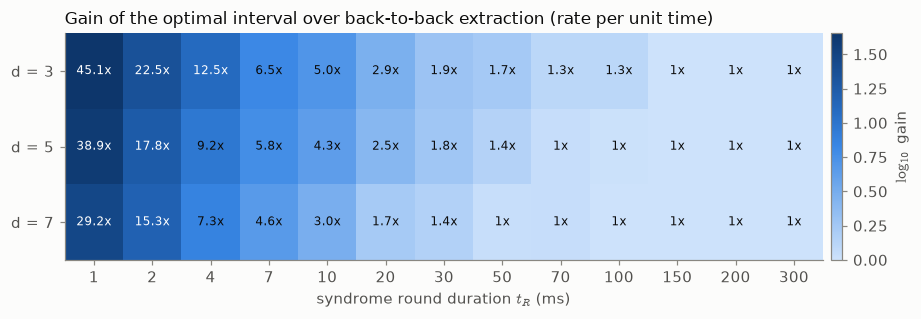

In [4]:
fig, ax = plt.subplots(figsize=(8.5, 3.0))
G = np.array([[cell[(t, d)]["gain"] if (t, d) in cell else np.nan for t in T_R] for d in DS])
top = np.nanmax(np.log10(G))
im = ax.imshow(np.log10(G), aspect="auto", cmap=P.sequential_cmap(), vmin=0, vmax=top)
for i, d in enumerate(DS):
    for j, t in enumerate(T_R):
        r = cell.get((t, d))
        if r:
            txt = f"{r['gain']:.1f}x" if r["regime"] == "wait" else "1x"
            ax.text(j, i, txt, ha="center", va="center", fontsize=8,
                    color="white" if np.log10(r["gain"]) > 0.6 * top else P.INK)
ax.set_xticks(range(len(T_R)), [f"{t*1e3:g}" for t in T_R])
ax.set_yticks(range(len(DS)), [f"d = {d}" for d in DS])
ax.set_xlabel("syndrome round duration $t_R$ (ms)"); ax.grid(False)
ax.set_title("Gain of the optimal interval over back-to-back extraction (rate per unit time)", loc="left")
fig.colorbar(im, ax=ax, label=r"$\log_{10}$ gain", fraction=0.025, pad=0.01)
fig.tight_layout()
P.save(fig, "08_regime_on_h2_1")

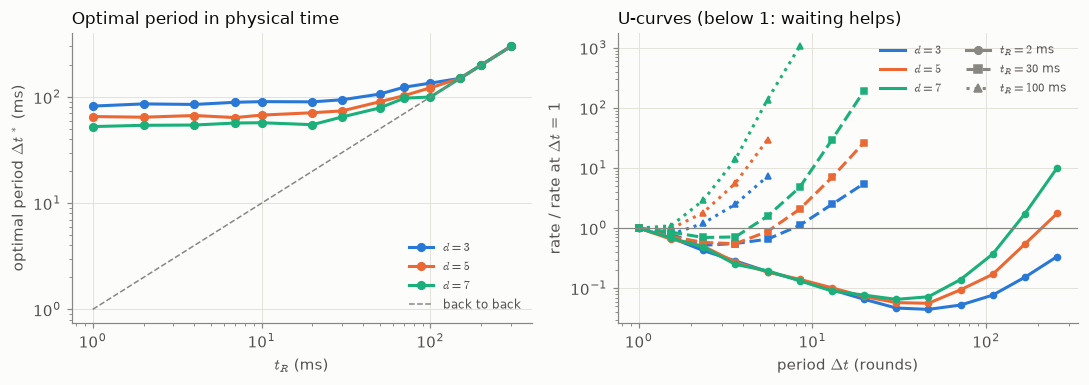

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for d in DS:
    ts = [t for t in T_R if (t, d) in cell]
    axes[0].plot([t * 1e3 for t in ts], [cell[(t, d)]["dt_star_seconds"] * 1e3 for t in ts], "o-",
                 color=P.D_COLOR[d], label=P.dl(d))
axes[0].plot([T_R[0] * 1e3, T_R[-1] * 1e3], [T_R[0] * 1e3, T_R[-1] * 1e3], "--", color=P.MUTED, lw=1,
             label="back to back")
axes[0].set_xscale("log"); axes[0].set_yscale("log"); axes[0].legend(fontsize=8)
axes[0].set_xlabel(r"$t_R$ (ms)"); axes[0].set_ylabel(r"optimal period $\Delta t^*$ (ms)")
axes[0].set_title("Optimal period in physical time", loc="left")
from matplotlib.lines import Line2D
TS = {0.002: ("-", "o"), 0.03: ("--", "s"), 0.1: (":", "^")}
for d in DS:
    for t, (ls, mk) in TS.items():
        r = cell.get((t, d))
        if not r:
            continue
        pts = [p for p in r["points"] if p.get("used")]
        axes[1].plot([p["dt"] for p in pts], [p["r"] / pts[0]["r"] for p in pts], ls, marker=mk, ms=4,
                     color=P.D_COLOR[d])
axes[1].axhline(1, color=P.MUTED, lw=0.8)
h = [Line2D([], [], color=P.D_COLOR[d], lw=2, label=P.dl(d)) for d in DS]
h += [Line2D([], [], color=P.MUTED, ls=ls, marker=mk, label=rf"$t_R = {t*1e3:g}$ ms") for t, (ls, mk) in TS.items()]
axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].legend(handles=h, fontsize=8, ncol=2)
axes[1].set_xlabel(r"period $\Delta t$ (rounds)"); axes[1].set_ylabel(r"rate / rate at $\Delta t$ = 1")
axes[1].set_title("U-curves (below 1: waiting helps)", loc="left")
fig.tight_layout()
P.save(fig, "08_regime_on_h2_2")

**Reading.**
- *Measured:* the answer is set by the idle error accumulated per round relative to the
  two-qubit gate error. With rounds of a few ms, idling per round is ~10⁻⁵, far below
  p2 = 10⁻³, and waiting tens of rounds lowers the logical error rate per unit time by an
  order of magnitude or more. As t_R grows the gain shrinks, and once idle error per round
  approaches p2 (t_R ≈ 0.1 s) back to back is best at d ≥ 5.
- *Measured:* while waiting pays, the optimal period in **seconds** stays in a narrow band
  and shortens with distance (the paper's 1/Δt* ∝ d, here in physical time).
- *Interp.:* the decisive unknown for H2 is t_R. Quantinuum's early 7-qubit colour-code
  experiment reported ~200 ms per QEC round (via arXiv 2208.08064; not an H2 figure), which
  would sit in the back-to-back region; faster rounds move a device left on this map. It
  has to be measured on the device.
- *Modelling limits:* the 2π reading of the quadratic rate ("cycles", the conservative
  choice) and equal layer durations are assumptions; the "radians" reading moves dt* by ~4×.
  At d = 7 and short t_R, failures are rare and some points hit the shot cap.